## <center> **Part 2: Recommend classic rock songs and build Neural Networks only with numpy** <center>
### <center> **Mia Mac** <center>

### **IV. Neural Network Using Numpy**

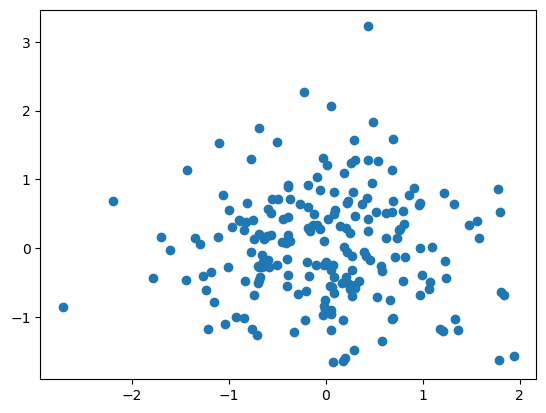

In [1]:
from sklearn.datasets import make_gaussian_quantiles
import matplotlib.pyplot as plt

samples = 200
def load_extra_datasets(N):  
    gaussian_quantiles = make_gaussian_quantiles(mean=None, 
                                                 cov=0.7, 
                                                 n_samples=N, 
                                                 n_features=2, 
                                                 n_classes=2,  
                                                 shuffle=True, 
                                                 random_state=42)
    return  gaussian_quantiles

gaussian_quantiles= load_extra_datasets(samples)

X, Y = gaussian_quantiles

X, Y = X.T, Y.reshape(1, Y.shape[0])

#print(Y)
# Visualize the data
plt.scatter(X[0, :], X[1, :]) #, c=Y, s=40);
plt.show()

In [2]:
n_x = X.shape[0] # size of input layer`
n_h = 4
n_y = Y.shape[0] # size of output layer

print(n_x, n_y)

2 1


In [3]:
import numpy as np

W1 = np.random.randn(n_h,n_x) * 0.01
b1 = np.zeros(shape=(n_h, 1))
W2 = np.random.randn(n_y,n_h) * 0.01
b2 = np.zeros(shape=(n_y, 1))

print("W1\n", W1)
print("b1\n", b1)
print("W2\n", W2)
print("b2\n", b2)

W1
 [[-0.01252308 -0.00387853]
 [ 0.010179   -0.01386587]
 [-0.01999579  0.02149482]
 [ 0.0034585   0.01073243]]
b1
 [[0.]
 [0.]
 [0.]
 [0.]]
W2
 [[-0.007615    0.01122016 -0.00156964  0.01331166]]
b2
 [[0.]]


In [4]:
def sigmoid(x):
    return 1 / (1 + np.e ** -x)

total_cost = -9999

In [5]:
# Implement Forward Propagation to calculate A2 (probabilities)
Z1 = np.dot(W1,X) + b1
A1 = np.tanh(Z1)
Z2 = np.dot(W2,A1) + b2
A2 = sigmoid(Z2) # Final output prediction

print(b2)

[[0.]]


In [6]:
# Compute the cross-entropy cost
old_total_cost = total_cost
cost_function = np.multiply(np.log(A2), Y) + np.multiply((1 - Y), np.log(1 - A2)) #J(theta)
total_cost = -np.sum(cost_function) / samples

print("cost=", total_cost)
print("cost delta=", np.subtract(total_cost, old_total_cost))

cost= 0.6931403911934979
cost delta= 9999.693140391193


In [7]:
print(Z1.shape)
print(A1.shape)
print(Z2.shape)
print(A2.shape)
print(cost_function.shape)

(4, 200)
(4, 200)
(1, 200)
(1, 200)
(1, 200)


In [8]:
dJdZ2 = A2 - Y
dJdW2 = (1 / samples) * np.dot(dJdZ2, A1.T)
dJdb2 = (1 / samples) * np.sum(dJdZ2, axis=1, keepdims=True)
# since activation function is tanh(Z1) = A1
# first derivative of d/dz tanh(z) = 1 - tanh(z) ^ 2 = 1 - A1 ^ 2
dJdZ1 = np.multiply(np.dot(W2.T, dJdZ2), 1 - np.power(A1, 2))
dJdW1 = (1 / samples) * np.dot(dJdZ1, X.T)
dJdb1 = (1 / samples) * np.sum(dJdZ1, axis=1, keepdims=True)

print("dJdZ2=", dJdZ2)
print("dJdW2=", dJdW2)
print("dJdb2=", dJdb2)
print("dJdW1=", dJdW1)
print("dJdb1=", dJdb1)

dJdZ2= [[ 0.4999738   0.50002388  0.49998739 -0.50008194  0.49996162  0.4999699
   0.49993809 -0.50003218 -0.50001125 -0.49999246  0.50000372 -0.49993406
   0.49995222 -0.50000436  0.50003356 -0.49998656  0.49995466 -0.49994682
   0.5000024   0.50003524  0.50000776  0.50001283  0.50000447 -0.5000862
  -0.49998747 -0.50009332 -0.50008949  0.49995072  0.50001992 -0.4998874
  -0.50007383 -0.5001909  -0.49994931  0.50002867  0.50001685  0.50000695
  -0.49990792  0.4999464  -0.49994091 -0.50010155 -0.49992756 -0.50011508
   0.49999416 -0.49997425  0.49997383 -0.49995737  0.49998555  0.50001407
  -0.49995603  0.49998889  0.49997839  0.50004285 -0.49992171  0.50005905
  -0.50006129 -0.49994632 -0.49989546  0.49999412 -0.49995941  0.50001368
   0.49998794 -0.49999097 -0.49999091 -0.49987356  0.50001341  0.49998925
   0.49999205 -0.49992122 -0.49993872 -0.50004547 -0.49992755  0.50002725
   0.50000504 -0.50007042  0.50004657  0.50002399  0.49995445 -0.50006958
  -0.50007938  0.50003031  0.50002

In [9]:
learning_rates = [0.0001, 0.01, 1]

for lr in learning_rates:
    # Re-initialize weights fresh for each learning rate
    np.random.seed(42)
    W1 = np.random.randn(n_h, n_x) * 0.01
    b1 = np.zeros((n_h, 1))
    W2 = np.random.randn(n_y, n_h) * 0.01
    b2 = np.zeros((n_y, 1))
    
    print(f"\nLearning Rate: {lr}")
    
    for i in range(10):  # 10 iterations
        # Forward prop
        Z1 = np.dot(W1, X) + b1
        A1 = np.tanh(Z1)
        Z2 = np.dot(W2, A1) + b2
        A2 = sigmoid(Z2)
        
        # Backprop
        dJdZ2 = A2 - Y
        dJdW2 = (1/samples) * np.dot(dJdZ2, A1.T)
        dJdb2 = (1/samples) * np.sum(dJdZ2, axis=1, keepdims=True)
        dJdZ1 = np.multiply(np.dot(W2.T, dJdZ2), 1 - np.power(A1, 2))
        dJdW1 = (1/samples) * np.dot(dJdZ1, X.T)
        dJdb1 = (1/samples) * np.sum(dJdZ1, axis=1, keepdims=True)
        
        # Update weights
        b2_old = b2.copy()
        W1 -= lr * dJdW1
        b1 -= lr * dJdb1
        W2 -= lr * dJdW2
        b2 -= lr * dJdb2
        
        delta_b2 = b2 - b2_old
        print(f"  Iter {i+1}: b2 before={b2_old[0,0]:.8f}, after={b2[0,0]:.8f}, delta={delta_b2[0,0]:.8e}")


Learning Rate: 0.0001
  Iter 1: b2 before=0.00000000, after=-0.00000000, delta=-4.52590059e-11
  Iter 2: b2 before=-0.00000000, after=-0.00000000, delta=-4.52586558e-11
  Iter 3: b2 before=-0.00000000, after=-0.00000000, delta=-4.52583057e-11
  Iter 4: b2 before=-0.00000000, after=-0.00000000, delta=-4.52579555e-11
  Iter 5: b2 before=-0.00000000, after=-0.00000000, delta=-4.52576054e-11
  Iter 6: b2 before=-0.00000000, after=-0.00000000, delta=-4.52572554e-11
  Iter 7: b2 before=-0.00000000, after=-0.00000000, delta=-4.52569053e-11
  Iter 8: b2 before=-0.00000000, after=-0.00000000, delta=-4.52565552e-11
  Iter 9: b2 before=-0.00000000, after=-0.00000000, delta=-4.52562051e-11
  Iter 10: b2 before=-0.00000000, after=-0.00000000, delta=-4.52558551e-11

Learning Rate: 0.01
  Iter 1: b2 before=0.00000000, after=-0.00000000, delta=-4.52590059e-09
  Iter 2: b2 before=-0.00000000, after=-0.00000001, delta=-4.52239929e-09
  Iter 3: b2 before=-0.00000001, after=-0.00000001, delta=-4.51890685

#### **Discussion**
The delta change in b2 is defined as delta b2 equals negative learning rate times dJ/db2, meaning it is directly proportional to the learning rate. 

- With a learning rate of 0.0001, the delta b2 is approximately negative 4.52e-11. These are negligible updates where gradient descent takes extremely small steps, risking very slow convergence.
- With a learning rate of 0.01, the delta b2 is approximately negative 4.52e-09, which is 100 times larger as expected from a 100 times increase in learning rate, producing stable and consistent updates.
- With a learning rate of 1, the delta b2 is approximately negative 4.52e-07, which is 10,000 times larger than the smallest learning rate, producing aggressive updates that risk overshooting the loss minimum.

At a learning rate of 1, the magnitude of delta b2 decreases across iterations, going from negative 4.52e-07 down to negative 3.32e-07. This is because as the weights shift, the gradient dJ/db2 itself changes. The model is moving through the loss surface and the local slope is decreasing, suggesting the optimizer is making progress toward a local minimum despite the large step size.